In [1]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path
import os
from tqdm import tqdm

In [2]:
logdir = "runs"
reader = SummaryReader(logdir, extra_columns={"dir_name"})

In [40]:
data = reader.scalars
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")
data["run_seed"] = data["run_name"].str.split("_").str[-1]
data["aux_weight"] = data["run_name"].str.split("_").str[-2].str[1:]
data["value_smoothed"] = data["value"].rolling(window=10).mean()
data

,step,tag,value,run_name,run_category,run_seed,aux_weight,value_smoothed
0,0,aux/r2_score_angular_velocity_y,-36.760838,all_w0.1_s0,all,s0,0.1,NaN
1,1,aux/r2_score_angular_velocity_y,-12.740454,all_w0.1_s0,all,s0,0.1,NaN
2,2,aux/r2_score_angular_velocity_y,-0.709868,all_w0.1_s0,all,s0,0.1,NaN
3,3,aux/r2_score_angular_velocity_y,-0.812792,all_w0.1_s0,all,s0,0.1,NaN
4,4,aux/r2_score_angular_velocity_y,-0.419878,all_w0.1_s0,all,s0,0.1,NaN
...,...,...,...,...,...,...,...,...
5562577,595,total_loss,0.777437,wheel_slip_rear_lateral_w1_s2,wheel_slip_rear_lateral,s2,1,0.760207
5562578,596,total_loss,0.807580,wheel_slip_rear_lateral_w1_s2,wheel_slip_rear_lateral,s2,1,0.771157
5562579,597,total_loss,0.793396,wheel_slip_rear_lateral_w1_s2,wheel_slip_rear_lateral,s2,1,0.776294
5562580,598,total_loss,0.767980,wheel_slip_rear_lateral_w1_s2,wheel_slip_rear_lateral,s2,1,0.778227


In [12]:
def auc(g):
    return np.trapezoid(g["value"], g["step"])


completed_runs = data[data["step"] == 599]

rewards = data[(data["tag"] == "reward/mean")].sort_values("step")
# get only the ones that are finished
rewards = rewards[rewards.groupby("run_name")["step"].transform("max") >= 599]

auc_df = (
    rewards.groupby(["run_category", "aux_weight", "run_seed"])
           .apply(auc, include_groups=False)
           .rename("auc")
           .reset_index()
)
last_n = 50

last_steps_mean_reward = (
    rewards[rewards["step"] > 599 - last_n]          # steps 550-599 (50 steps)
    .groupby(["run_category", "aux_weight", "run_seed"])["value"]
    .mean()
    .rename("last_50_mean_reward")
    .reset_index()
)
last_steps_mean_reward

,run_category,aux_weight,run_seed,last_50_mean_reward
0,all,0.1,s0,0.175062
1,all,0.1,s1,0.161085
2,all,0.1,s2,0.168969
3,all,0.3,s0,0.162019
4,all,0.3,s1,0.171508
...,...,...,...,...
101,wheel_slip_rear_lateral,0.3,s1,0.174625
102,wheel_slip_rear_lateral,0.3,s2,0.098033
103,wheel_slip_rear_lateral,1,s0,0.158871
104,wheel_slip_rear_lateral,1,s1,0.057452


<Axes: xlabel='step', ylabel='value_smoothed'>

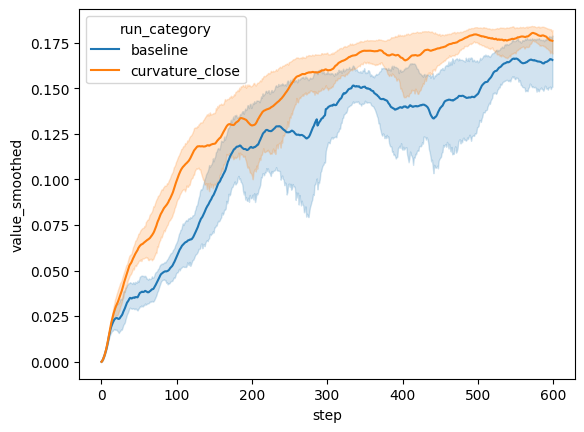

In [41]:
sns.lineplot(data[data["run_category"].isin(["baseline", "curvature_close"]) & (data["tag"] == "reward/mean")], x="step", y="value_smoothed", hue="run_category")

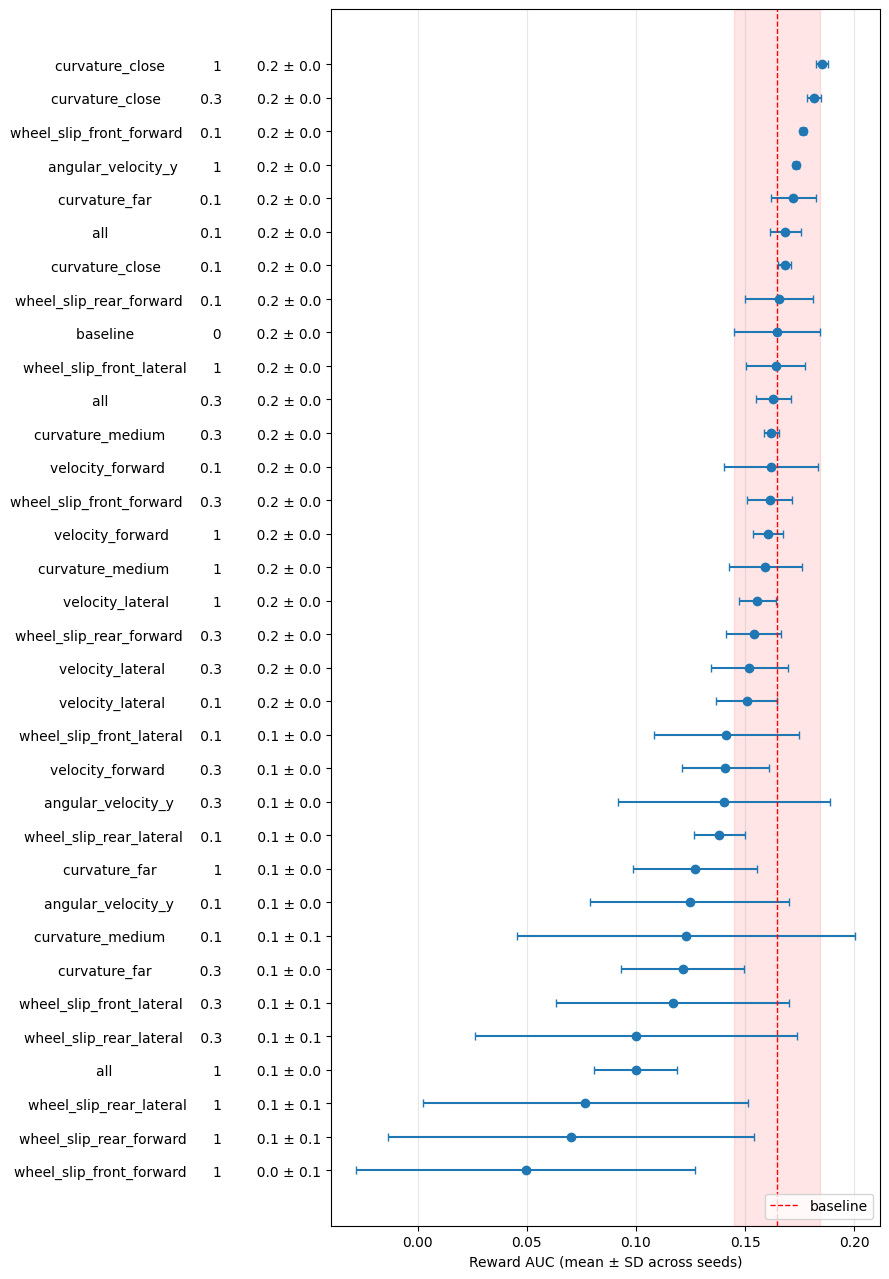

In [31]:
summary = (
    last_steps_mean_reward.groupby(["run_category", "aux_weight"])["last_50_mean_reward"]
    .agg(mean="mean", std="std", count="count")
    .reset_index()
    .sort_values("mean")
    .reset_index(drop=True)
)

labels = [
    f"{r.run_category:<20} {r.aux_weight:>6}   {r['mean']:8.1f} ± {r['std']:.1f}"
    for _, r in summary.iterrows()
]

fig, ax = plt.subplots(figsize=(9, 0.35 * len(summary) + 1))
ax.errorbar(summary["mean"], summary.index,
            xerr=summary["std"], fmt="o", capsize=3)

ax.set_yticks(summary.index, labels)
ax.set_xlabel("Reward AUC (mean ± SD across seeds)")
ax.grid(axis="x", alpha=0.3)

base = summary[summary["run_category"] == "baseline"].iloc[0]

ax.axvline(base["mean"], color="red", ls="--", lw=1, label="baseline")
ax.axvspan(base["mean"] - base["std"], base["mean"] +
           base["std"], color="red", alpha=0.1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/figures/primary_task_auc_dumbbells.pdf")

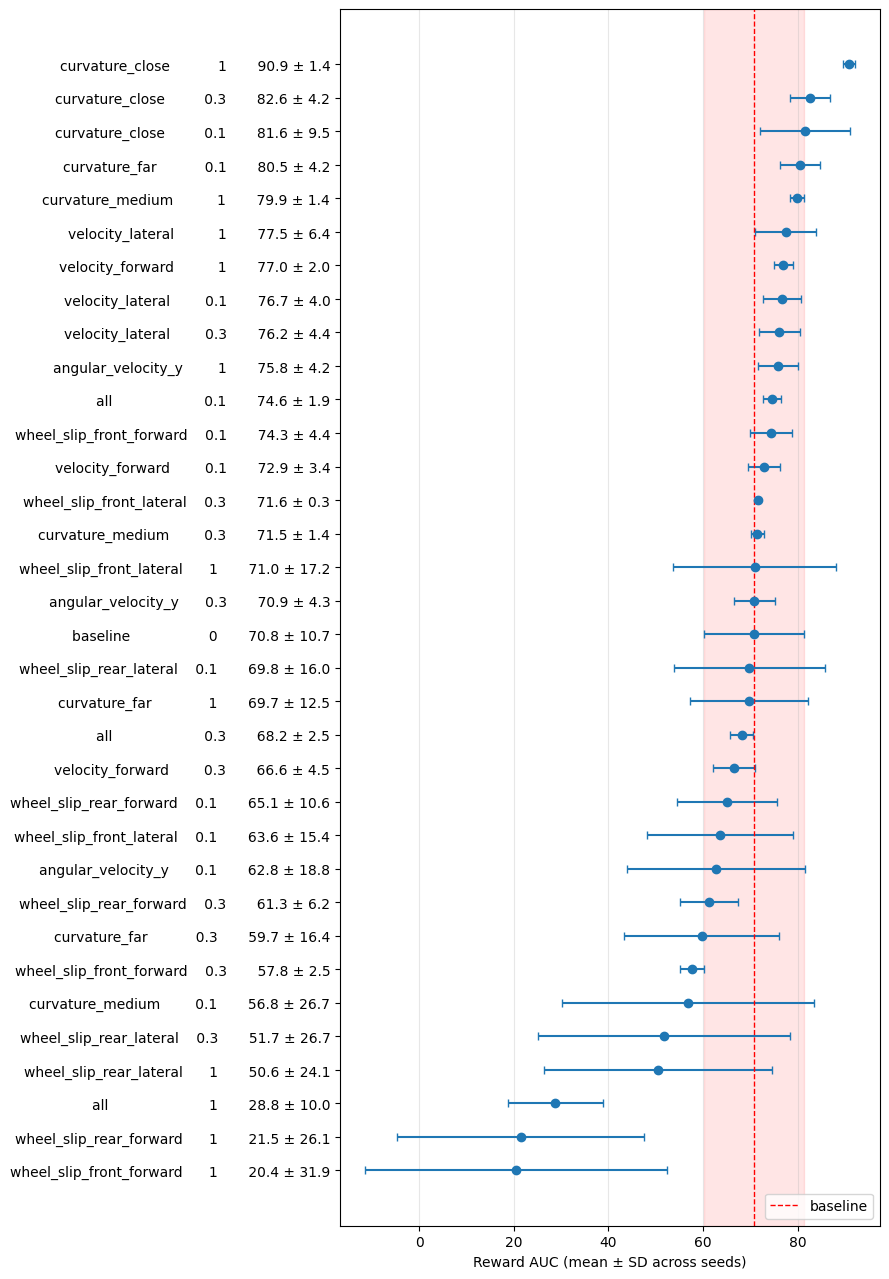

In [ ]:
summary = (
    auc_df.groupby(["run_category", "aux_weight"])["auc"]
          .agg(["mean", "std"])
          .reset_index()
          .sort_values("mean")
          .reset_index(drop=True)
)

labels = [
    f"{r.run_category:<20} {r.aux_weight:>6}   {r['mean']:8.1f} ± {r['std']:.1f}"
    for _, r in summary.iterrows()
]

fig, ax = plt.subplots(figsize=(9, 0.35 * len(summary) + 1))
ax.errorbar(summary["mean"], summary.index, xerr=summary["std"], fmt="o", capsize=3)

ax.set_yticks(summary.index, labels)
ax.set_xlabel("Reward AUC (mean ± SD across seeds)")
ax.grid(axis="x", alpha=0.3)

base = summary[summary["run_category"] == "baseline"].iloc[0]

ax.axvline(base["mean"], color="red", ls="--", lw=1, label="baseline")
ax.axvspan(base["mean"] - base["std"], base["mean"] + base["std"], color="red", alpha=0.1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/figures/primary_task_auc_dumbbells.pdf")